In [1]:
import pandas as pd

In [2]:
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)

In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
from sklearn.datasets import  make_blobs


In [9]:
X_custom , y_custom = make_blobs(n_samples=100, centers=4, cluster_std=0.7, random_state=42)

In [10]:
# Convert to DataFrame for easier handling and consistent plotting
df_custom = pd.DataFrame(X_custom, columns=['features_1','features_2'])
df_custom['cluster'] = y_custom

In [12]:
# Sample point for Demonstration
sample_index_custom = 50
sample_point_custom = df_custom.iloc[[sample_index_custom]][['features_1', 'features_2']]
sample_cluster_custom = df_custom.iloc[sample_index_custom]['cluster']

In [13]:
print(f"Custom dataset generated with {len(df_custom)} points.")

Custom dataset generated with 100 points.


In [15]:
df_custom.head()

,features_1,features_2,cluster
0,-9.431083,6.263130,3
1,-6.310165,-7.741715,2
2,-2.837830,9.394078,0
3,-5.897671,-7.861405,2
4,-8.587877,7.716072,3


# Visualizing Nearest Neighbors using Euclidean distance

In [16]:
from sklearn.neighbors import NearestNeighbors
import  matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [17]:
# Prepare the data: X should only contain numerical features
X = df[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
y = df['species']


In [19]:
# Choose a sample point for demonstration(e.g., the 50th data point which is Iris-versicolor)
sample_index = 50

# Use only numerical features for the sample point for KNN calculation preserving DataFrame structure
sample_point= X.iloc[[sample_index]]
sample_species = y.iloc[sample_index]

# Number of Neighbors to visualize
k = 5

In [22]:
# Update X, y, sample_index, sample_point, and sample_species to use the custom dataset
X = df_custom[['features_1', 'features_2']]
y = df_custom['cluster']

In [23]:
sample_index = sample_index_custom
sample_point = sample_point_custom
sample_species = sample_cluster_custom

k = 5

In [24]:
# Train a NearestNeighbors model with Euclidean distance
knn_euclidean = NearestNeighbors(n_neighbors=k , metric='euclidean')
knn_euclidean.fit(X)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [31]:
distance_euclidian , indices_euclidean =knn_euclidean.kneighbors(sample_point)

sns.set_theme(style='whitegrid')

<Axes: xlabel='features_1', ylabel='features_2'>

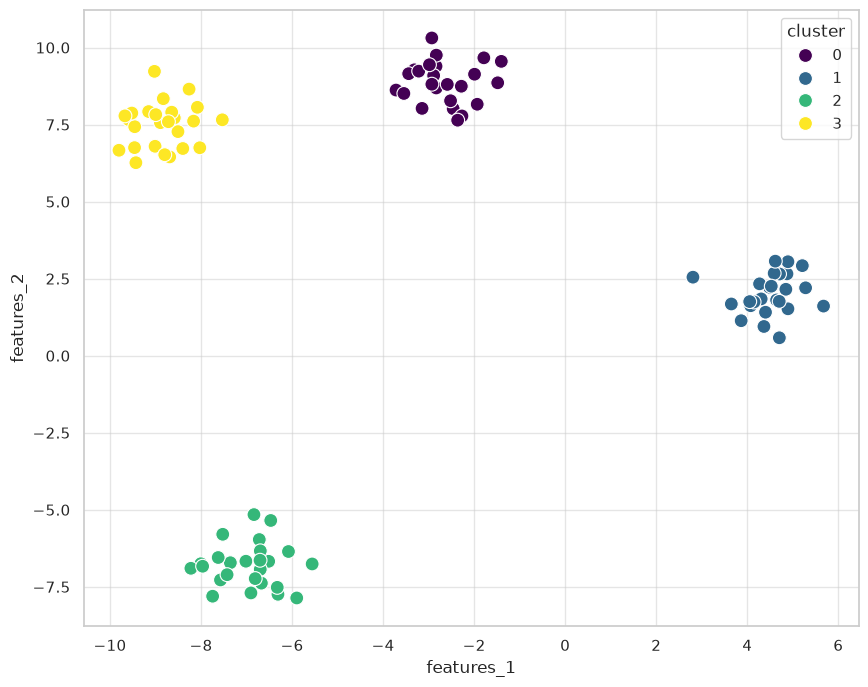

In [32]:
# Create the plot
plt.figure(figsize=(10, 8))
sns.scatterplot(x='features_1', y='features_2', hue='cluster', data=df_custom, palette='viridis', s=100)


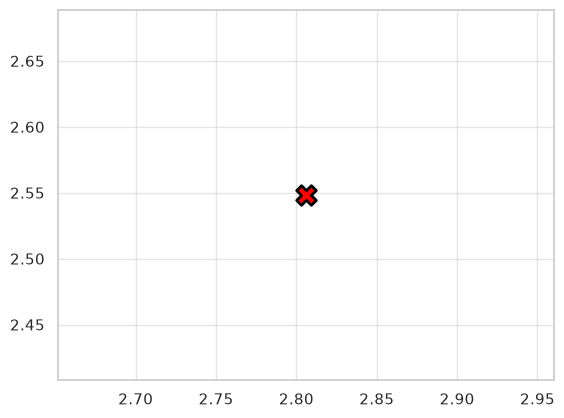

In [33]:
# Highlight the sample point
plt.scatter(sample_point.iloc[0]['features_1'],
            sample_point.iloc[0]['features_2'],
            color='red', marker='X', s=200, label=f'Sample Point (Cluster {sample_species})', edgecolors='black', linewidths=2
            )

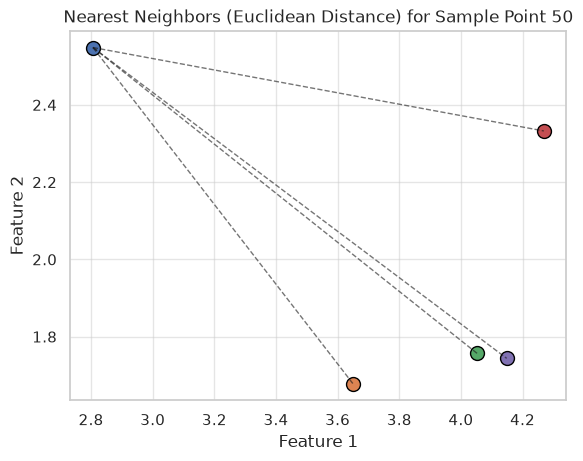

In [39]:
# Draw lines to nearest neighbors without distinct color
for i, neighbor_index in enumerate(indices_euclidean[0]):
    neighbor_point = X.iloc[neighbor_index]
    plt.plot([sample_point.iloc[0]['features_1'], neighbor_point['features_1']],
             [sample_point.iloc[0]['features_2'], neighbor_point['features_2']],
             'k--', alpha=0.6, linewidth=1)
    plt.scatter(neighbor_point['features_1'], neighbor_point['features_2'], # Not coloring nearest neighbors differently
                marker='o', s=100, edgecolor='black', linewidth=1)


plt.title(f'Nearest Neighbors (Euclidean Distance) for Sample Point {sample_index}')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()